# Data Pipeline and Tool Mastery: Global Superstore
**Name:** Arifa Begum R

## 1. Introduction
**Objective:** build a small ETL pipeline (Extract, Transform, Load) and show proficiency in three industry tools.

| Tool | Used for |
|---|---|
| Python and Pandas | extracting and transforming data |
| SQL (SQLite) | storing data and answering business questions |
| Matplotlib and Seaborn | visualizing the results |

**Dataset:** Global Superstore (51,290 orders, 2011 to 2014).

In [2]:
%mamba install pandas matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.847 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy          1.0.3    py313h1804a44_0      emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
+ seaborn        0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base   0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels    0.14.6   np23py313hd8db738_2  emscripten-forge-4x
- pip            26.2.1   pyh145f28c_0         conda-forge


In [3]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)
print("SQLite:", sqlite3.sqlite_version)

Pandas: 3.0.6
Seaborn: 0.13.2
SQLite: 3.47.2


## 2. Extract (Pandas)

In [4]:
path = Path("data/Global_Superstore2.csv")
if not path.exists():
    path = Path("Global_Superstore2.csv")

raw = pd.read_csv(path, encoding="latin-1")
print("Shape:", raw.shape)
raw.head()

Shape: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [5]:
print(raw.dtypes)
print()
print("Missing values:")
print(raw.isnull().sum()[raw.isnull().sum() > 0])
print("Duplicates:", raw.duplicated().sum())

Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID           str
Customer Name         str
Segment               str
City                  str
State                 str
Country               str
Postal Code       float64
Market                str
Region                str
Product ID            str
Category              str
Sub-Category          str
Product Name          str
Sales             float64
Quantity            int64
Discount          float64
Profit            float64
Shipping Cost     float64
Order Priority        str
dtype: object

Missing values:
Postal Code    41296
dtype: int64
Duplicates: 0


**Insight (extract):**
- The file loaded correctly with 24 columns: 17 text columns, 5 decimal columns and 2 whole-number columns.
- Order Date and Ship Date are stored as text in day-month-year format (for example 31-07-2012). I must give the format when converting them, or Pandas may confuse the day and the month.
- Postal Code is the only column with missing values: 41,296 rows are empty, and it is filled only for United States orders. There are no duplicate rows.
- Some column names contain spaces or hyphens (Sub-Category, Shipping Cost), which are awkward to use in SQL. I will rename every column to lowercase with underscores.
- The same customer name can have different customer IDs. Rick Hansen appears as RH-19495 (United States) and RH-9495 (a different market), so IDs may be separate per market. To count customers I should use Customer ID, not the name.

## 3. Transform (Pandas)
The cleaning steps are written as one function, so the same pipeline can run again on new data.

In [6]:
def clean_orders(raw):
    """Clean the raw Global Superstore data and return a tidy DataFrame."""
    df = raw.copy()

    # 1. Drop columns that are not useful
    df = df.drop(columns=["Postal Code", "Row ID"])

    # 2. Standardise column names for SQL (lowercase, underscores)
    df.columns = (df.columns.str.strip().str.lower()
                  .str.replace(" ", "_").str.replace("-", "_"))

    # 3. Fix data types: text to datetime (day-month-year)
    df["order_date"] = pd.to_datetime(df["order_date"], format="%d-%m-%Y")
    df["ship_date"] = pd.to_datetime(df["ship_date"], format="%d-%m-%Y")

    # 4. Create new columns
    df["order_year"] = df["order_date"].dt.year
    df["order_month"] = df["order_date"].dt.month
    df["delivery_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["is_loss"] = (df["profit"] < 0).astype(int)
    df["discount_band"] = pd.cut(
        df["discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
        labels=["No discount", "Low (0-20%)", "Medium (20-40%)", "High (>40%)"]
    ).astype(str)

    return df

orders = clean_orders(raw)
print("Shape:", orders.shape)
print(list(orders.columns))

Shape: (51290, 27)
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'city', 'state', 'country', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority', 'order_year', 'order_month', 'delivery_days', 'is_loss', 'discount_band']


In [7]:
checks = {
    "No missing values": orders.isnull().sum().sum() == 0,
    "No duplicate rows": orders.duplicated().sum() == 0,
    "Ship date is not before order date": (orders["delivery_days"] >= 0).all(),
    "Discount is between 0 and 1": orders["discount"].between(0, 1).all(),
    "Quantity is positive": (orders["quantity"] > 0).all(),
    "Sales is positive": (orders["sales"] > 0).all(),
    "Order years are 2011 to 2014": orders["order_year"].between(2011, 2014).all(),
}

report = pd.DataFrame({"Check": checks.keys(),
                       "Result": ["PASS" if v else "FAIL" for v in checks.values()]})
report

,Check,Result
0,No missing values,PASS
1,No duplicate rows,PASS
2,Ship date is not before order date,PASS
3,Discount is between 0 and 1,PASS
4,Quantity is positive,PASS
5,Sales is positive,PASS
6,Order years are 2011 to 2014,PASS


**Insight (transform):**
- The cleaning function turned 24 raw columns into 27 tidy ones: 2 were dropped (Postal Code and Row ID), and 5 were added (order_year, order_month, delivery_days, is_loss and discount_band).
- All 7 data quality checks passed. No dates are out of order, no discounts are outside 0 to 1, and no sales or quantities are zero or negative, so the data is reliable for analysis.
- Keeping the cleaning inside one function makes the pipeline repeatable: new data can be cleaned with one line, `clean_orders(raw)`, and the checks tell me straight away if something breaks.
- Column names are now lowercase with underscores, which keeps the SQL queries short and free of quotes.

## 4. Load (SQLite)
The cleaned data is saved in a SQL database so it can be queried with SQL.

In [8]:
# Close and remove any broken database file from the failed attempt
import os
try:
    conn.close()
except Exception:
    pass
if os.path.exists("superstore.db"):
    os.remove("superstore.db")

# In-memory SQLite database (works in browser Jupyter)
conn = sqlite3.connect(":memory:")

# SQLite has no date type, so dates are stored as text in YYYY-MM-DD format
orders_db = orders.copy()
orders_db["order_date"] = orders_db["order_date"].dt.strftime("%Y-%m-%d")
orders_db["ship_date"] = orders_db["ship_date"].dt.strftime("%Y-%m-%d")

orders_db.to_sql("orders", conn, if_exists="replace", index=False)

# Indexes make queries on these columns faster
conn.execute("CREATE INDEX IF NOT EXISTS idx_year ON orders(order_year)")
conn.execute("CREATE INDEX IF NOT EXISTS idx_category ON orders(category)")
conn.execute("CREATE INDEX IF NOT EXISTS idx_market ON orders(market)")
conn.commit()
print("Loaded", len(orders_db), "rows into table 'orders'")

Loaded 51290 rows into table 'orders'


In [9]:
def run_sql(query):
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql(query, conn)

print(run_sql("SELECT COUNT(*) AS total_rows FROM orders"))
run_sql("SELECT order_id, order_date, category, sales, profit FROM orders LIMIT 5")

   total_rows
0       51290


,order_id,order_date,category,sales,profit
0,CA-2012-124891,2012-07-31,Technology,2309.650,762.1845
1,IN-2013-77878,2013-02-05,Furniture,3709.395,-288.7650
2,IN-2013-71249,2013-10-17,Technology,5175.171,919.9710
3,ES-2013-1579342,2013-01-28,Technology,2892.510,-96.5400
4,SG-2013-4320,2013-11-05,Technology,2832.960,311.5200


**Insight (load):**
- All 51,290 cleaned rows were loaded into an SQLite table called `orders`, and the first five rows match the cleaned DataFrame (dates are now stored as YYYY-MM-DD text, which is how SQLite keeps dates).
- I created indexes on order_year, category and market so queries that filter or group by these columns run faster.
- The database is created in memory, because the browser version of Jupyter cannot write database files. Because the whole pipeline (extract, transform, load) runs from the CSV in seconds, the database can be rebuilt at any time, which keeps the pipeline repeatable.

## 5. Query (SQL)
Six business questions answered with SQL.

In [10]:
# Q1 - overall KPIs
run_sql("""
SELECT COUNT(*) AS orders,
       COUNT(DISTINCT customer_id) AS customers,
       ROUND(SUM(sales), 0) AS total_sales,
       ROUND(SUM(profit), 0) AS total_profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS margin_pct,
       ROUND(AVG(is_loss) * 100, 1) AS loss_orders_pct
FROM orders
""")

,orders,customers,total_sales,total_profit,margin_pct,loss_orders_pct
0,51290,1590,12642502.0,1467457.0,11.6,24.5


In [11]:
#Q2 - five weakest sub-categories by profit
q2 = run_sql("""
SELECT category, sub_category,
       ROUND(SUM(sales), 0) AS sales,
       ROUND(SUM(profit), 0) AS profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS margin_pct
FROM orders
GROUP BY category, sub_category
ORDER BY profit ASC
LIMIT 5
""")
q2

,category,sub_category,sales,profit,margin_pct
0,Furniture,Tables,757042.0,-64083.0,-8.5
1,Office Supplies,Fasteners,83242.0,11525.0,13.8
2,Office Supplies,Labels,73404.0,15011.0,20.4
3,Office Supplies,Supplies,243074.0,22583.0,9.3
4,Office Supplies,Envelopes,170904.0,29601.0,17.3


In [12]:
#Q3 - markets ranked by margin (window function)
q3 = run_sql("""
SELECT market,
       ROUND(SUM(sales), 0) AS sales,
       ROUND(SUM(profit), 0) AS profit,
       ROUND(SUM(profit) * 100.0 / SUM(sales), 1) AS margin_pct,
       RANK() OVER (ORDER BY SUM(profit) * 1.0 / SUM(sales) DESC) AS margin_rank
FROM orders
GROUP BY market
ORDER BY margin_rank
""")
q3

,market,sales,profit,margin_pct,margin_rank
0,Canada,66928.0,17817.0,26.6,1
1,EU,2938089.0,372830.0,12.7,2
2,US,2297201.0,286397.0,12.5,3
3,APAC,3585744.0,436000.0,12.2,4
4,Africa,783773.0,88872.0,11.3,5
5,LATAM,2164605.0,221643.0,10.2,6
6,EMEA,806161.0,43898.0,5.4,7


In [13]:
#Q4 - discount bands
q4 = run_sql("""
SELECT discount_band,
       COUNT(*) AS orders,
       ROUND(AVG(profit), 2) AS avg_profit,
       ROUND(SUM(profit), 0) AS total_profit,
       ROUND(AVG(is_loss) * 100, 1) AS loss_orders_pct
FROM orders
GROUP BY discount_band
ORDER BY avg_profit DESC
""")
q4

,discount_band,orders,avg_profit,total_profit,loss_orders_pct
0,No discount,29009,61.04,1770695.0,0.0
1,Low (0-20%),10953,46.69,511444.0,21.6
2,Medium (20-40%),4367,-42.88,-187271.0,76.2
3,High (>40%),6961,-90.13,-627411.0,98.4


In [14]:
# Q5 - yearly sales growth (LAG window function)
q5 = run_sql("""
SELECT order_year,
       ROUND(SUM(sales), 0) AS sales,
       ROUND((SUM(sales) - LAG(SUM(sales)) OVER (ORDER BY order_year)) * 100.0
             / LAG(SUM(sales)) OVER (ORDER BY order_year), 1) AS sales_growth_pct
FROM orders
GROUP BY order_year
ORDER BY order_year
""")
q5

,order_year,sales,sales_growth_pct
0,2011,2259451.0,NaN
1,2012,2677439.0,18.5
2,2013,3405746.0,27.2
3,2014,4299866.0,26.3


In [15]:
# Q6 - weak-margin market and category pairs (CTE)
q6 = run_sql("""
WITH market_cat AS (
    SELECT market, category, SUM(sales) AS sales, SUM(profit) AS profit
    FROM orders
    GROUP BY market, category
)
SELECT market, category,
       ROUND(sales, 0) AS sales,
       ROUND(profit, 0) AS profit,
       ROUND(profit * 100.0 / sales, 1) AS margin_pct
FROM market_cat
WHERE profit * 100.0 / sales < 8
ORDER BY margin_pct ASC
""")
q6

,market,category,sales,profit,margin_pct
0,US,Furniture,742000.0,18451.0,2.5
1,EMEA,Furniture,228621.0,11534.0,5.0
2,LATAM,Furniture,811971.0,41598.0,5.1
3,EMEA,Office Supplies,276686.0,14869.0,5.4
4,EMEA,Technology,300855.0,17494.0,5.8


**Insight (SQL queries):**
- **Q1, KPIs:** the store made 51,290 orders from 1,590 customers (about 32 orders per customer), with total sales of 12.64M, total profit of 1.47M and an overall margin of 11.6%. 24.5% of all orders lose money.
- **Q2, weakest sub-categories:** Tables is the only sub-category that loses money: -64,083 profit on 757,042 sales (a margin of -8.5%). The other four (Fasteners, Labels, Supplies, Envelopes) are profitable and appear only because their total profit is small. Without Tables, the Furniture margin would be about 10.4% instead of 6.9%, so Tables is the main reason Furniture earns so little.
- **Q3, markets by margin:** Canada ranks first (26.6%), but it is tiny (66,928 sales). EU, US and APAC are close together (12.2% to 12.7%). EMEA ranks last at 5.4%, less than half of the next lowest market, LATAM (10.2%).
- **Q4, discount bands:** this is the clearest result. Orders with no discount never lose money (0.0%). Loss-making orders rise to 21.6% with a low discount, 76.2% with a medium discount and 98.4% with a high discount. About 81% of all loss-making orders (roughly 10,200 of 12,544) have a discount above 20%.
- **Q5, yearly growth:** sales grew 18.5% in 2012, 27.2% in 2013 and 26.3% in 2014, so 2014 sales (4.30M) were almost double those of 2011 (2.26M).
- **Q6, weak market and category pairs:** five pairs have a margin below 8%. US Furniture is the lowest at 2.5% even though its sales are 742,000. Furniture appears in three of the five pairs (US, EMEA, LATAM), and EMEA appears three times (Furniture, Office Supplies and Technology), which shows that EMEA's weak margin is not caused by one category.

## 6. Visualize (Matplotlib and Seaborn)
Charts built from the SQL query results.

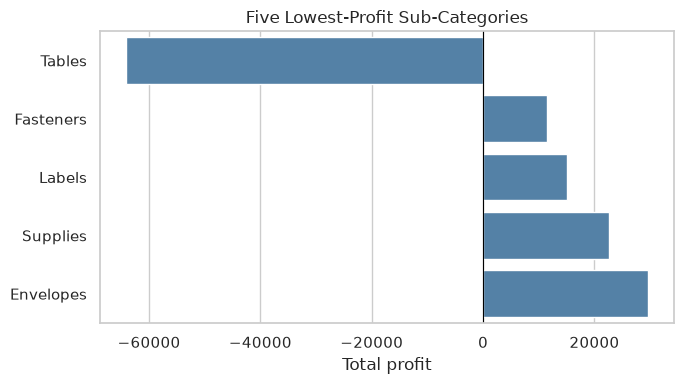

In [16]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 4))
sns.barplot(data=q2, x="profit", y="sub_category", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Five Lowest-Profit Sub-Categories")
plt.xlabel("Total profit")
plt.ylabel("")
plt.tight_layout()
plt.show()

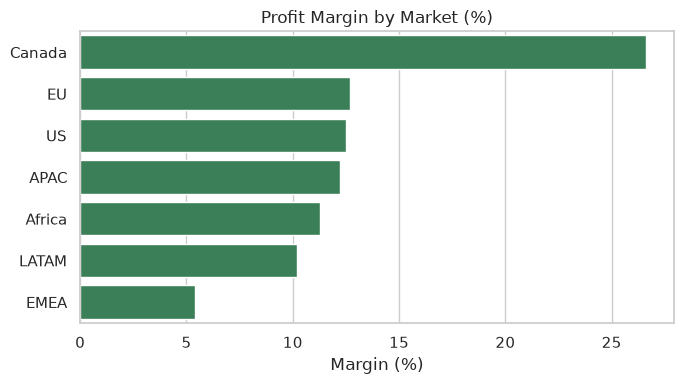

In [17]:
plt.figure(figsize=(7, 4))
sns.barplot(data=q3, x="margin_pct", y="market", color="seagreen")
plt.title("Profit Margin by Market (%)")
plt.xlabel("Margin (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

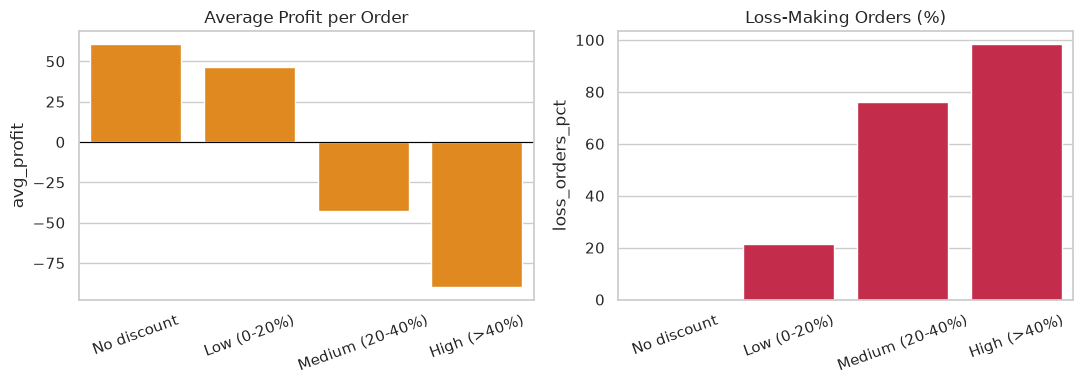

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=q4, x="discount_band", y="avg_profit", color="darkorange", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Average Profit per Order")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=q4, x="discount_band", y="loss_orders_pct", color="crimson", ax=axes[1])
axes[1].set_title("Loss-Making Orders (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

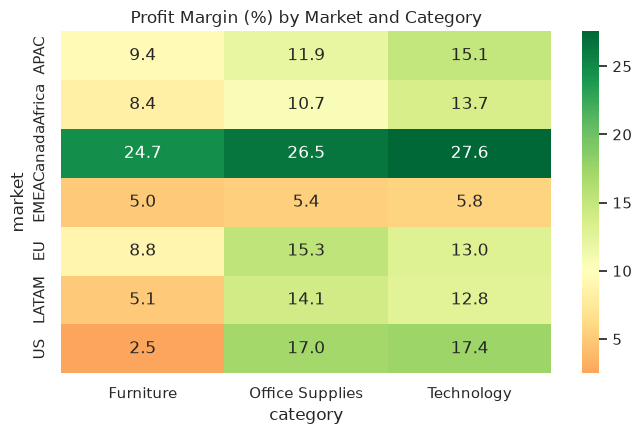

category,Furniture,Office Supplies,Technology
market,,,
APAC,9.4,11.9,15.1
Africa,8.4,10.7,13.7
Canada,24.7,26.5,27.6
EMEA,5.0,5.4,5.8
EU,8.8,15.3,13.0
LATAM,5.1,14.1,12.8
US,2.5,17.0,17.4


In [19]:
heat = run_sql("""
SELECT market, category, SUM(profit) * 100.0 / SUM(sales) AS margin_pct
FROM orders
GROUP BY market, category
""").pivot(index="market", columns="category", values="margin_pct")

plt.figure(figsize=(7, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn", center=10)
plt.title("Profit Margin (%) by Market and Category")
plt.tight_layout()
plt.show()
heat.round(1)

**Insight (charts):**
- **Lowest-profit sub-categories:** Tables is the only bar below zero (about -64,000), and it stands out clearly from the four small but profitable sub-categories.
- **Margin by market:** EMEA has the shortest bar (5.4%) among the major markets. Canada's bar is the longest, but Canada is too small to compare fairly.
- **Discount bands:** average profit falls from about +61 with no discount to about -90 with a high discount, while the share of loss-making orders rises from 0% to 98.4%. The two charts show the same story from two sides.
- **Heatmap:** the weakest cell is US Furniture (2.5%). Furniture is the lowest or among the lowest category in most markets (US 2.5%, EMEA 5.0%, LATAM 5.1%, Africa 8.4%, EU 8.8%, APAC 9.4%), while Technology is the highest in most markets. EMEA is red across all three categories (5.0% to 5.8%), which confirms that its problem affects the whole market, not one product line.

## 7. Pandas vs SQL: the same question in both tools
Question: what is the average profit and loss rate for each discount band?

In [25]:
pandas_q4 = (orders.groupby("discount_band")
             .agg(orders=("profit", "size"),
                  avg_profit=("profit", "mean"),
                  total_profit=("profit", "sum"),
                  loss_orders_pct=("is_loss", "mean"))
             .round({"avg_profit": 2, "total_profit": 0}))
pandas_q4["loss_orders_pct"] = (pandas_q4["loss_orders_pct"] * 100).round(1)
pandas_q4 = pandas_q4.sort_values("avg_profit", ascending=False)
print(pandas_q4)

merged = q4.set_index("discount_band").join(pandas_q4, rsuffix="_pd")
same = all((merged[c] - merged[c + "_pd"]).abs().max() < 0.01
           for c in ["orders", "avg_profit", "total_profit", "loss_orders_pct"])
print("\nSQL and Pandas give the same result:", same)

                 orders  avg_profit  total_profit  loss_orders_pct
discount_band                                                     
No discount       29009       61.04     1770695.0              0.0
Low (0-20%)       10953       46.69      511444.0             21.6
Medium (20-40%)    4367      -42.88     -187271.0             76.2
High (>40%)        6961      -90.13     -627411.0             98.4

SQL and Pandas give the same result: True


**Insight (Pandas vs SQL):**
- The same question gave exactly the same result in both tools: 29,009 orders with no discount averaged +61.04 profit, and 6,961 orders with a discount above 40% averaged -90.13, with 98.4% of them making a loss.
- Because the answers match, I can trust the SQL queries, and I can choose the tool by where the data lives and who needs it, not by which one is "more correct".
- The Pandas version is better inside a Python workflow, because it works directly on the cleaned DataFrame. The SQL version is easier to read for non-programmers and can run straight on a database.

## 8. The Full Pipeline in One Function
Extract, transform, check and load are combined so the whole process can be repeated with one line.

In [26]:
def run_pipeline(csv_path):
    """Extract, transform, validate and load the data. Returns a database connection and the row count."""
    raw = pd.read_csv(csv_path, encoding="latin-1")           # Extract
    clean = clean_orders(raw)                                  # Transform

    assert clean.isnull().sum().sum() == 0, "Missing values found"      # Validate
    assert clean.duplicated().sum() == 0, "Duplicate rows found"
    assert (clean["delivery_days"] >= 0).all(), "Ship date before order date"
    assert clean["discount"].between(0, 1).all(), "Discount out of range"

    db_data = clean.copy()                                     # Load
    db_data["order_date"] = db_data["order_date"].dt.strftime("%Y-%m-%d")
    db_data["ship_date"] = db_data["ship_date"].dt.strftime("%Y-%m-%d")
    connection = sqlite3.connect(":memory:")
    db_data.to_sql("orders", connection, index=False)
    return connection, len(db_data)

conn2, rows = run_pipeline(path)
print("Pipeline finished. Rows loaded:", rows)
print(pd.read_sql("SELECT COUNT(*) AS rows_in_db FROM orders", conn2))

Pipeline finished. Rows loaded: 51290
   rows_in_db
0       51290


## 9. Tool Comparison

| Tool | What I used it for | Strengths | Limits |
|---|---|---|---|
| Pandas | Loading, cleaning, new columns, validation | Flexible, easy to clean and reshape data in Python | Everything is held in memory, so very large data is slow |
| SQL (SQLite) | Storing data and answering 6 business questions | Short, readable queries; window functions and CTEs; works on large data with indexes | Needs structured tables; less flexible for cleaning |
| Matplotlib and Seaborn | Bar charts and a heatmap | Seaborn gives clean charts with little code; Matplotlib gives full control | Charts are static, not interactive |

**When I would use each:** Pandas to prepare data, SQL to store it and ask repeated questions, and Seaborn to present the findings. The same discount question gave the same answer in Pandas and in SQL, so the choice depends on where the data lives and who needs to use it.

## 10. Conclusion
In this task I built a small ETL pipeline for the Global Superstore data and showed three tools:
- **Pandas:** extracted the CSV, cleaned it with a reusable function, and ran 7 data quality checks that all passed.
- **SQL:** loaded 51,290 rows into SQLite and answered six business questions using GROUP BY, window functions (RANK and LAG) and a CTE.
- **Seaborn and Matplotlib:** turned the query results into charts and a heatmap.

**Main findings:** orders with no discount never lost money, while 98.4% of orders with a discount above 40% did. About 81% of all loss-making orders had a discount above 20%. Tables is the only sub-category that loses money (-64,083), and EMEA has a low margin (5.4%) in all three categories.

**Next step:** apply the same pipeline idea to a new dataset and load it into a PostgreSQL database.